# Lab 9 — Gyroscope sensor parameters (TRIK, yaw axis)

**Goal.** Identify the parameters of the TRIK gyroscope and build a simulated gyro from them:

$$\omega_{meas}(t_k) = Q_{\Delta}\Big(\mathrm{sat}_{\pm\omega_{max}}\big[(1+s)\,\omega_{true}(t_k) + b_0 + d\,t_k + n_k\big]\Big), \quad n_k \sim \mathcal{N}(0,\sigma^2)$$

**Experiment** (`lab9_gyro.qrs`, same program as text in `lab9_gyro.js`; **Option A**, open loop, in-place rotation $u_R = u$, $u_L = -u$):

| Phase | What the robot does | Duration |
|---|---|---|
| warm-up | still, not logged | 2 min |
| `static` | still, logged | 3 min |
| `sin` | $u = \mathrm{sat}_{\pm100}(A\sin(2\pi t/4))$, A = 30 → 60 → 150 % (12 s each) | 36 s |
| `rect` | square wave ±1, T = 4 s, A = 30 → 60 → 150 % | 36 s |
| `rest` | still, logged | 3 s |

Log line every ~10 ms: `t_ms, t_us, gz_raw, gz_cal, encL, encR, u, phase` (phase as a name from the `.js`, as 0/1/2/3 from the `.qrs`) —
`t_ms` script time, `t_us` = `read()[3]`, `gz_raw` = `readRawData()[2]`, `gz_cal` = `read()[2]` (mdeg/s),
`encL` = E3, `encR` = E4 (degrees: `Encoder::read()` in trikRuntime converts ticks to degrees).

Reference heading from the wheels: $\theta_{enc} = \frac{r}{B}(\varphi_R - \varphi_L)$, $r$ = 0.042 m, $B$ = 0.194 m (Lab 5).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import cumulative_trapezoid
from IPython.display import Markdown, display

try:                                    # in Google Colab: upload lab9_gyro.csv
    from google.colab import files
    files.upload()
except ImportError:                     # locally: the csv is next to the notebook
    pass

SIM = False                             # True: log from lab9_gyro_sim.qrs (2D model), False: real robot
FILE = 'lab9_gyro_sim.csv' if SIM else 'lab9_gyro_real.csv'
FILE2 = 'lab9_gyro_run2.csv'                       # second run, compared in §11 (None to skip)
r, B = (0.028, 0.154) if SIM else (0.042, 0.194)   # wheel radius, track width, m (sim robot / real robot, Lab 5)
AMP = [30, 60, 150]                     # amplitudes A, %, 12 s each
TAPE_DEG = None                         # slip check: angle from the tape line (start direction) to the robot's
                                        # nose at the end, deg; + if the nose ended up to the LEFT (CCW). Fill in.

## 0. Loading, time base, units

- `read()[3]` is **not** in µs: trikRuntime packs the time as 1 unit = 256 µs (`TimeVal::packedUInt32`). The cell checks this against the script clock.
- The gyro is integrated with its own timestamps. If the loop reads the same gyro sample twice, the time step is 0, so it adds nothing to the integral. Statistics (b₀, σ, …) use each gyro sample once.

In [2]:
log = pd.read_csv(FILE)
num = ['t_ms', 't_us', 'gz_raw', 'gz_cal', 'encL', 'encR', 'u']
log[num] = log[num].apply(pd.to_numeric, errors='coerce')
log = log.dropna().reset_index(drop=True)            # drops a header line written twice, if any
codes = {'0': 'static', '1': 'sin', '2': 'rect', '3': 'rest'}   # the .qrs program logs the phase as a number
log['phase'] = log.phase.astype(str).str.strip().str.replace(r'\.0$', '', regex=True).replace(codes)

t = log.t_ms.to_numpy() / 1000                       # script time since the static phase started, s
tick = (np.diff(log.t_us.to_numpy(np.int64)) + 2**31) % 2**32 - 2**31   # gyro timestamp steps
unit = (t[-1] - t[0]) * 1e6 / tick.sum()             # µs per timestamp unit, measured
UNIT = 256.0 if abs(unit / 256 - 1) < 0.05 else unit
print(f'1 unit of read()[3] = {unit:.1f} µs (script clock)  ->  using {UNIT:g} µs')
t_g = np.r_[0, np.cumsum(tick)] * UNIT * 1e-6        # gyro time, s
new = np.r_[True, tick != 0]                         # row holds a new gyro sample

phase = log.phase.to_numpy()
raw, cal = log.gz_raw.to_numpy(float), log.gz_cal.to_numpy(float)
th_enc = r / B * (log.encR - log.encL).to_numpy(float)                   # heading from the wheels, deg
win = 2 * max(1, round(0.05 / np.median(np.diff(t)))) + 1               # ~0.1 s window, odd
th_s = pd.Series(th_enc).rolling(win, center=True, min_periods=1).mean()
w_enc = np.gradient(th_s, t)                                             # encoder yaw rate, deg/s
static, rot = phase == 'static', np.isin(phase, ['sin', 'rect', 'rest'])
def is_clip(v):    # gyro stuck at one extreme value while the wheels turn clearly faster, or at the 16-bit limit
    m = rot & (raw == v)
    return m.sum() >= 10 and (32700 <= abs(v) <= 32768 or np.median(np.abs(w_enc[m])) > 1.1 * abs(v) * 0.00875)
hi, lo = raw[rot].max(), raw[rot].min()
CLIP_HI = hi if is_clip(hi) else np.inf
CLIP_LO = lo if is_clip(lo) else -np.inf
clipped = (raw >= CLIP_HI) | (raw <= CLIP_LO)

for p in ['static', 'sin', 'rect', 'rest']:
    m = phase == p
    print(f'{p:6s}: {m.sum():6d} lines, {t[m][-1] - t[m][0]:6.1f} s, {np.sum(m & new):6d} gyro samples')
print(f'loop period: median {1000 * np.median(np.diff(t)):.1f} ms;  raw output clipped at {CLIP_LO} / {CLIP_HI} ({clipped.sum()} samples)')

1 unit of read()[3] = 255.9 µs (script clock)  ->  using 256 µs
static:   2312 lines,  179.9 s,   2312 gyro samples
sin   :    461 lines,   35.9 s,    461 gyro samples
rect  :    453 lines,   35.9 s,    453 gyro samples
rest  :     40 lines,    3.0 s,     40 gyro samples
loop period: median 76.0 ms;  raw output clipped at -32736.0 / 32764.0 (226 samples)


### Raw → deg/s factor and sign (§6, steps 1–2 — every other section needs them)

`read()[2]` = (raw − TRIK's own bias) × F, in mdeg/s, so the slope of `gz_cal` against `gz_raw` is F.
Fit on rotation samples that are not clipped; points where the two calls caught different gyro samples are dropped as outliers and the line is fitted again.

F = 8.7520 mdeg/s per raw unit  (L3GD20 datasheet at ±250 dps: 8.75)
693 of 728 rotation samples used
sign: raw > 0 when the wheels turn the robot CW


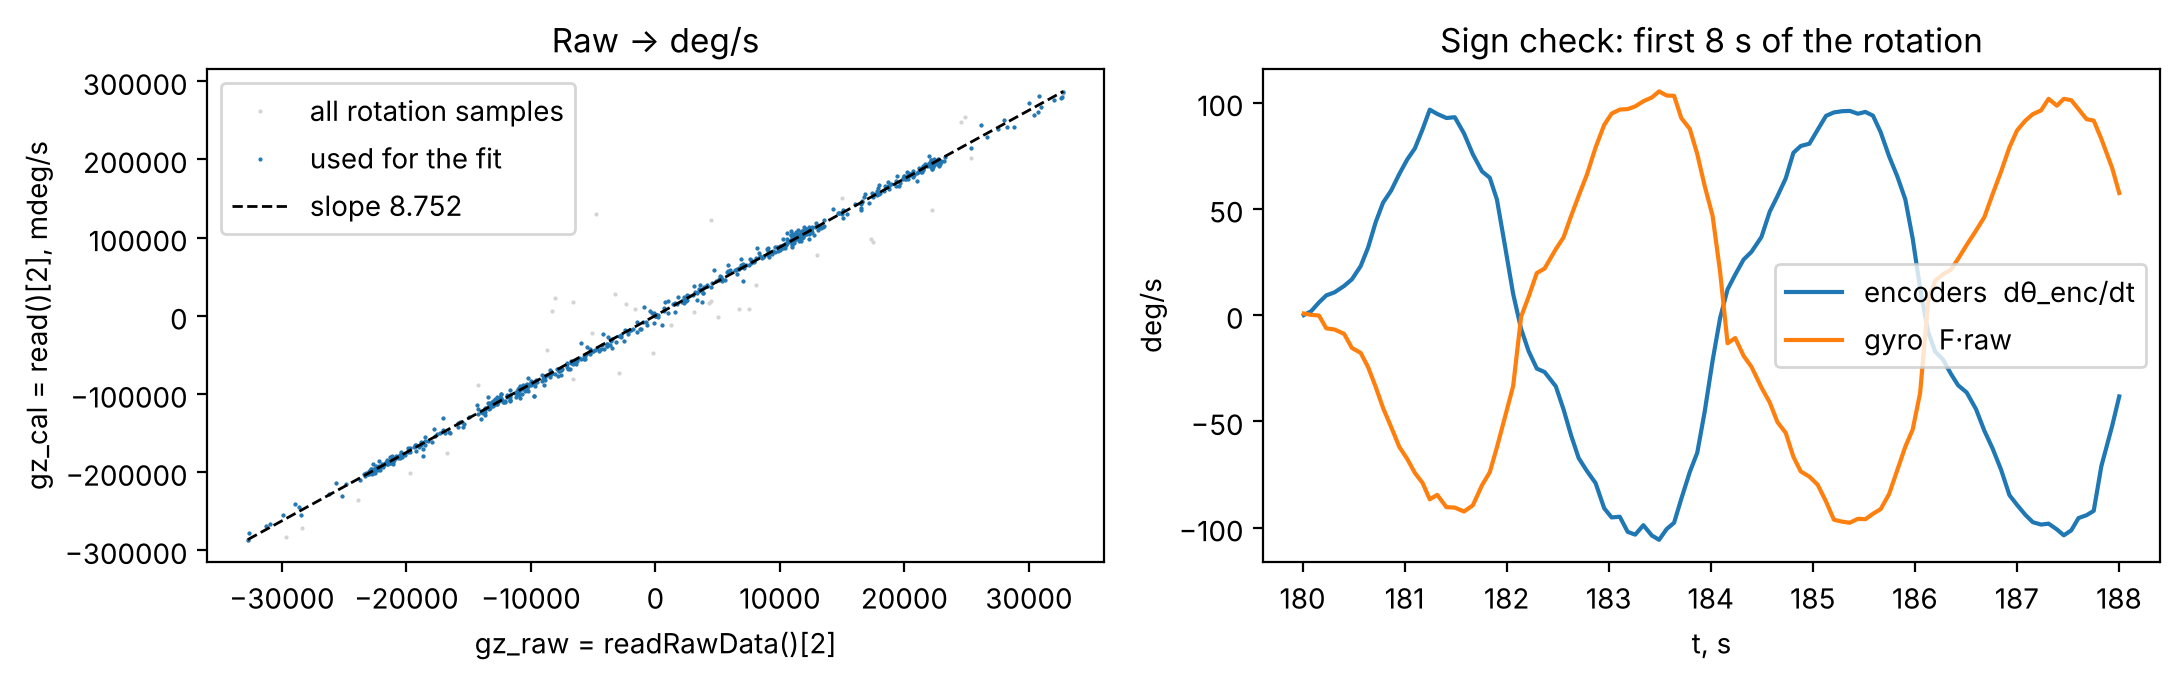

In [3]:
fit = rot & ~clipped
p1 = np.polyfit(raw[fit], cal[fit], 1)
res = cal - np.polyval(p1, raw)
keep = fit & (np.abs(res) < 5 * 1.4826 * np.median(np.abs(res[fit])) + 10)
slope, icpt = np.polyfit(raw[keep], cal[keep], 1)
F = slope / 1000                                     # deg/s per raw unit
SIGN = 1 if np.corrcoef(raw[rot], w_enc[rot])[0, 1] > 0 else -1   # gyro sign vs wheel heading (CCW +)
POS_DIR = 'CCW' if SIGN > 0 else 'CW'
w = SIGN * F * raw                                   # gyro rate, deg/s, CCW positive
print(f'F = {1000 * F:.4f} mdeg/s per raw unit  (L3GD20 datasheet at ±250 dps: 8.75)')
print(f'{keep.sum()} of {fit.sum()} rotation samples used')
print(f'sign: raw > 0 when the wheels turn the robot {POS_DIR}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(raw[rot], cal[rot], '.', ms=1, color='lightgrey', label='all rotation samples')
ax[0].plot(raw[keep], cal[keep], '.', ms=1, label='used for the fit')
xx = np.array([lo, hi]); ax[0].plot(xx, slope * xx + icpt, 'k--', lw=1, label=f'slope {slope:.3f}')
ax[0].set(xlabel='gz_raw = readRawData()[2]', ylabel='gz_cal = read()[2], mdeg/s', title='Raw → deg/s'); ax[0].legend()
sl = log.phase.eq('sin').to_numpy() & (t < t[rot][0] + 8)
ax[1].plot(t[sl], w_enc[sl], label='encoders  dθ_enc/dt')
ax[1].plot(t[sl], F * raw[sl], label='gyro  F·raw')
ax[1].set(xlabel='t, s', ylabel='deg/s', title='Sign check: first 8 s of the rotation'); ax[1].legend()
plt.tight_layout(); plt.show()

## 1. Offset (bias) $b_0$

Static log, first 30 s: $b_0 = \frac{1}{N}\sum\omega_k$, standard error $\sigma/\sqrt N$. Then $b_0(T)$ for T = 1 … 30 s.

b0 = -0.5392 ± 0.0035 deg/s   (first 30 s, N = 387)
  T =  1 s: b0 = -0.5084 ± 0.0217 deg/s
  T =  2 s: b0 = -0.5310 ± 0.0140 deg/s
  T =  5 s: b0 = -0.5212 ± 0.0072 deg/s
  T = 10 s: b0 = -0.5301 ± 0.0056 deg/s
  T = 20 s: b0 = -0.5423 ± 0.0043 deg/s
  T = 30 s: b0 = -0.5392 ± 0.0035 deg/s


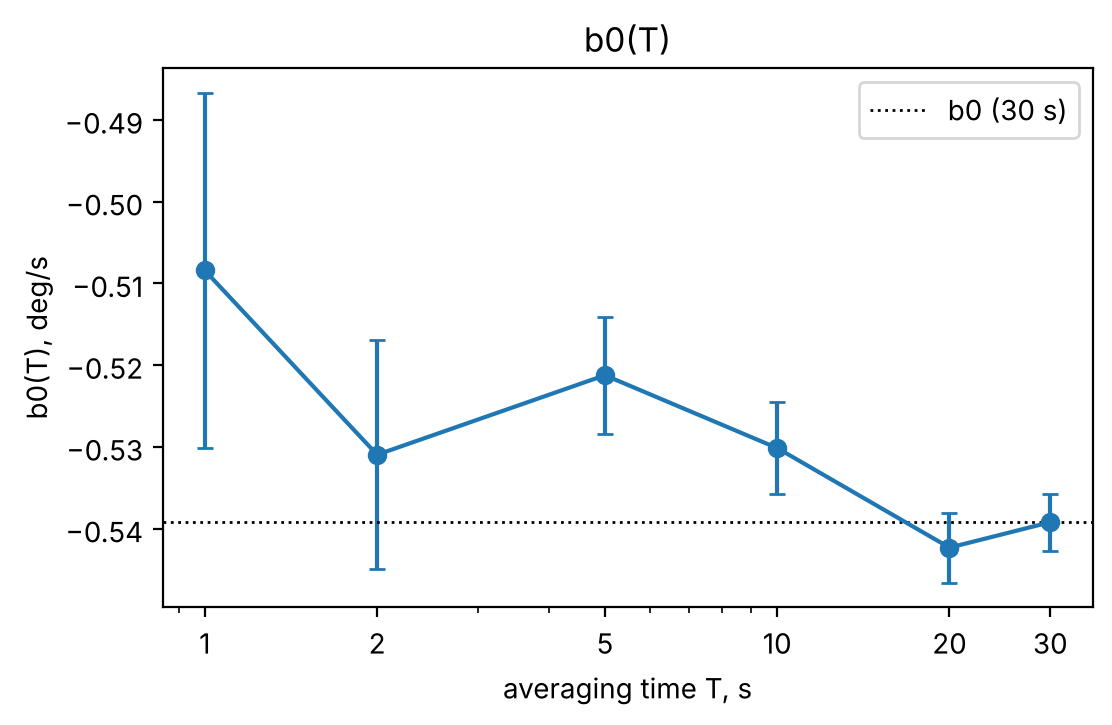

In [4]:
def static_samples(log):
    # time from the first static sample (s) and rate (deg/s) of every new gyro sample in the static phase
    m = (log.phase == 'static').to_numpy()
    tk = (np.diff(log.t_us.to_numpy(np.int64)[m]) + 2**31) % 2**32 - 2**31
    tt = np.r_[0, np.cumsum(tk)] * UNIT * 1e-6
    nw = np.r_[True, tk != 0]
    return tt[nw], SIGN * F * log.gz_raw.to_numpy(float)[m][nw]

ts, ws = static_samples(log)
Ts = np.median(np.diff(ts))                          # gyro sample period, s
first = ts < 30
b0 = ws[first].mean()
se = ws[first].std() / np.sqrt(first.sum())
print(f'b0 = {b0:.4f} ± {se:.4f} deg/s   (first 30 s, N = {first.sum()})')

T_list = [1, 2, 5, 10, 20, 30]
b0_T = [ws[ts < T].mean() for T in T_list]
se_T = [ws[ts < T].std() / np.sqrt(np.sum(ts < T)) for T in T_list]
for T, b, e in zip(T_list, b0_T, se_T):
    print(f'  T = {T:2d} s: b0 = {b:.4f} ± {e:.4f} deg/s')

plt.figure(figsize=(6, 3.5))
plt.errorbar(T_list, b0_T, yerr=se_T, fmt='o-', capsize=3)
plt.axhline(b0, color='k', ls=':', lw=1, label='b0 (30 s)')
plt.xscale('log'); plt.xticks(T_list, T_list)
plt.xlabel('averaging time T, s'); plt.ylabel('b0(T), deg/s'); plt.title('b0(T)'); plt.legend(); plt.show()

### My calibration method: `calibrate_gyro(log)`

1. Take the first `T_CAL` seconds of the static log.
2. **Spike rejection:** drop samples more than 4 robust σ from the median (robust σ = 1.4826 · MAD), so one bump or electrical spike cannot shift the result.
3. Return the mean of what is left.

On the robot this would be a running sum over `T_CAL` s, with the median taken from the first second.

**Choosing `T_CAL`:** the shortest T for which (a) the estimate is precise enough, ±2 standard errors within ±0.005 deg/s (0.3 deg/min, ≈ 1° in 3 min), and (b) the $b_0(T)$ curve is flat from there on (all longer T give a value within ±0.005 deg/s). Past that point a longer calibration only costs time.

b0(T) does not settle within ±0.005 deg/s inside 30 s (at 73 ms per sample the noise alone needs ~59 s of averaging for that): T_CAL = 30 s
T_CAL = 30 s,  calibrate_gyro(log) = -0.5392 deg/s


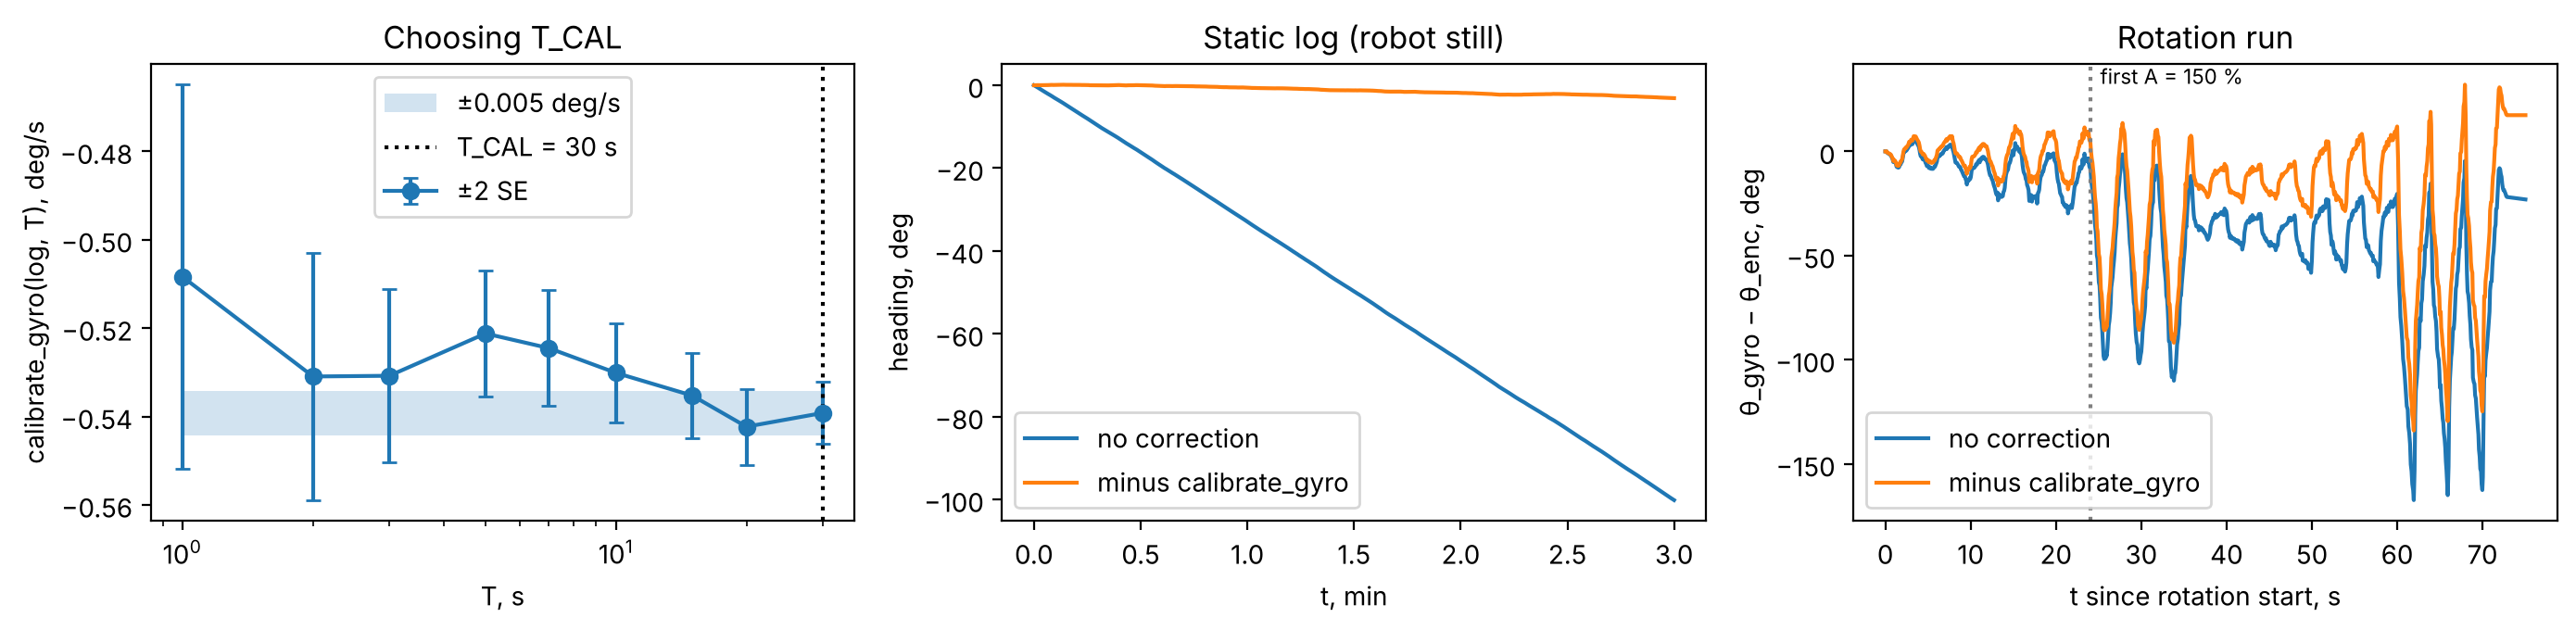

Heading error after 3 min still: -100.16 deg without correction, -3.11 deg with calibrate_gyro
Rotation run: removing b0 takes out -12.9 deg of the error over the 24 s before the first saturated turn. What is left swings with the heading (scale factor, §6) and with the saturated turns (§3, §7).


In [5]:
def calibrate_gyro(log, T_cal=None):
    # offset b0 from the static log: first T_cal s, spikes removed, then the mean (deg/s)
    tt, ww = static_samples(log)
    ww = ww[tt < (T_cal if T_cal else T_CAL)]
    med = np.median(ww)
    rsig = 1.4826 * np.median(np.abs(ww - med))
    good = np.abs(ww - med) <= 4 * max(rsig, F)
    return ww[good].mean()

TOL = 0.005                                          # deg/s
grid = [1, 2, 3, 5, 7, 10, 15, 20, 30]
b_grid = [calibrate_gyro(log, T) for T in grid]
se_grid = [ws[ts < T].std() / np.sqrt(np.sum(ts < T)) for T in grid]
ok = [T for i, T in enumerate(grid) if 2 * se_grid[i] <= TOL and all(abs(b - b_grid[i]) <= TOL for b in b_grid[i:])]
FLAT = len(ok) > 0 and ok[0] < 30
T_CAL = ok[0] if FLAT else 30                        # if b0(T) never flattens, use the longest time
if not FLAT: print(f'b0(T) does not settle within ±{TOL} deg/s inside 30 s (at {1000 * Ts:.0f} ms per sample the noise alone '
                   f'needs ~{(2 * ws.std() / TOL) ** 2 * Ts:.0f} s of averaging for that): T_CAL = 30 s')
b_cal = calibrate_gyro(log)
print(f'T_CAL = {T_CAL} s,  calibrate_gyro(log) = {b_cal:.4f} deg/s')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].errorbar(grid, b_grid, yerr=2 * np.array(se_grid), fmt='o-', capsize=3, label='±2 SE')
ax[0].fill_between(grid, b_grid[grid.index(T_CAL)] - TOL, b_grid[grid.index(T_CAL)] + TOL, alpha=0.2, label='±0.005 deg/s')
ax[0].axvline(T_CAL, color='k', ls=':', label=f'T_CAL = {T_CAL} s')
ax[0].set(xscale='log', xlabel='T, s', ylabel='calibrate_gyro(log, T), deg/s', title='Choosing T_CAL'); ax[0].legend()

th_raw = cumulative_trapezoid(ws, ts, initial=0)
th_c = cumulative_trapezoid(ws - b_cal, ts, initial=0)
ax[1].plot(ts / 60, th_raw, label='no correction')
ax[1].plot(ts / 60, th_c, label='minus calibrate_gyro')
ax[1].set(xlabel='t, min', ylabel='heading, deg', title='Static log (robot still)'); ax[1].legend()

tr = t_g[rot] - t_g[rot][0]
e_raw = cumulative_trapezoid(w[rot], tr, initial=0) - (th_enc[rot] - th_enc[rot][0])
e_cal = cumulative_trapezoid(w[rot] - b_cal, tr, initial=0) - (th_enc[rot] - th_enc[rot][0])
ax[2].plot(tr, e_raw, label='no correction')
ax[2].plot(tr, e_cal, label='minus calibrate_gyro')
ax[2].axvline(24, color='grey', ls=':'); ax[2].text(24.5, ax[2].get_ylim()[1], ' first A = 150 %', va='top', fontsize=8)
ax[2].set(xlabel='t since rotation start, s', ylabel='θ_gyro − θ_enc, deg', title='Rotation run'); ax[2].legend()
plt.tight_layout(); plt.show()

th_c180 = np.interp(180, ts, th_c)
print(f'Heading error after 3 min still: {np.interp(180, ts, th_raw):.2f} deg without correction, {th_c180:.2f} deg with calibrate_gyro')
print(f'Rotation run: removing b0 takes out {b_cal * 24:.1f} deg of the error over the 24 s before the first saturated turn. '
      f'What is left swings with the heading (scale factor, §6) and with the saturated turns (§3, §7).')

## 2. Bias drift $d$

Full 3-min static log, 30-s windows, line fit of the window means → $d$. Then the heading:
(a) raw rate → drift dominated by $b_0$; (b) rate − $b_0$ → residual drift.

d = -0.0072 deg/s/min
(a) uncorrected heading drift: -33.46 deg/min;  b0·60 = -32.35 deg/min
(b) heading error after 1 min with b0 removed: -0.58 deg
(b) heading error after 2 min with b0 removed: -1.86 deg
(b) heading error after 3 min with b0 removed: -3.11 deg


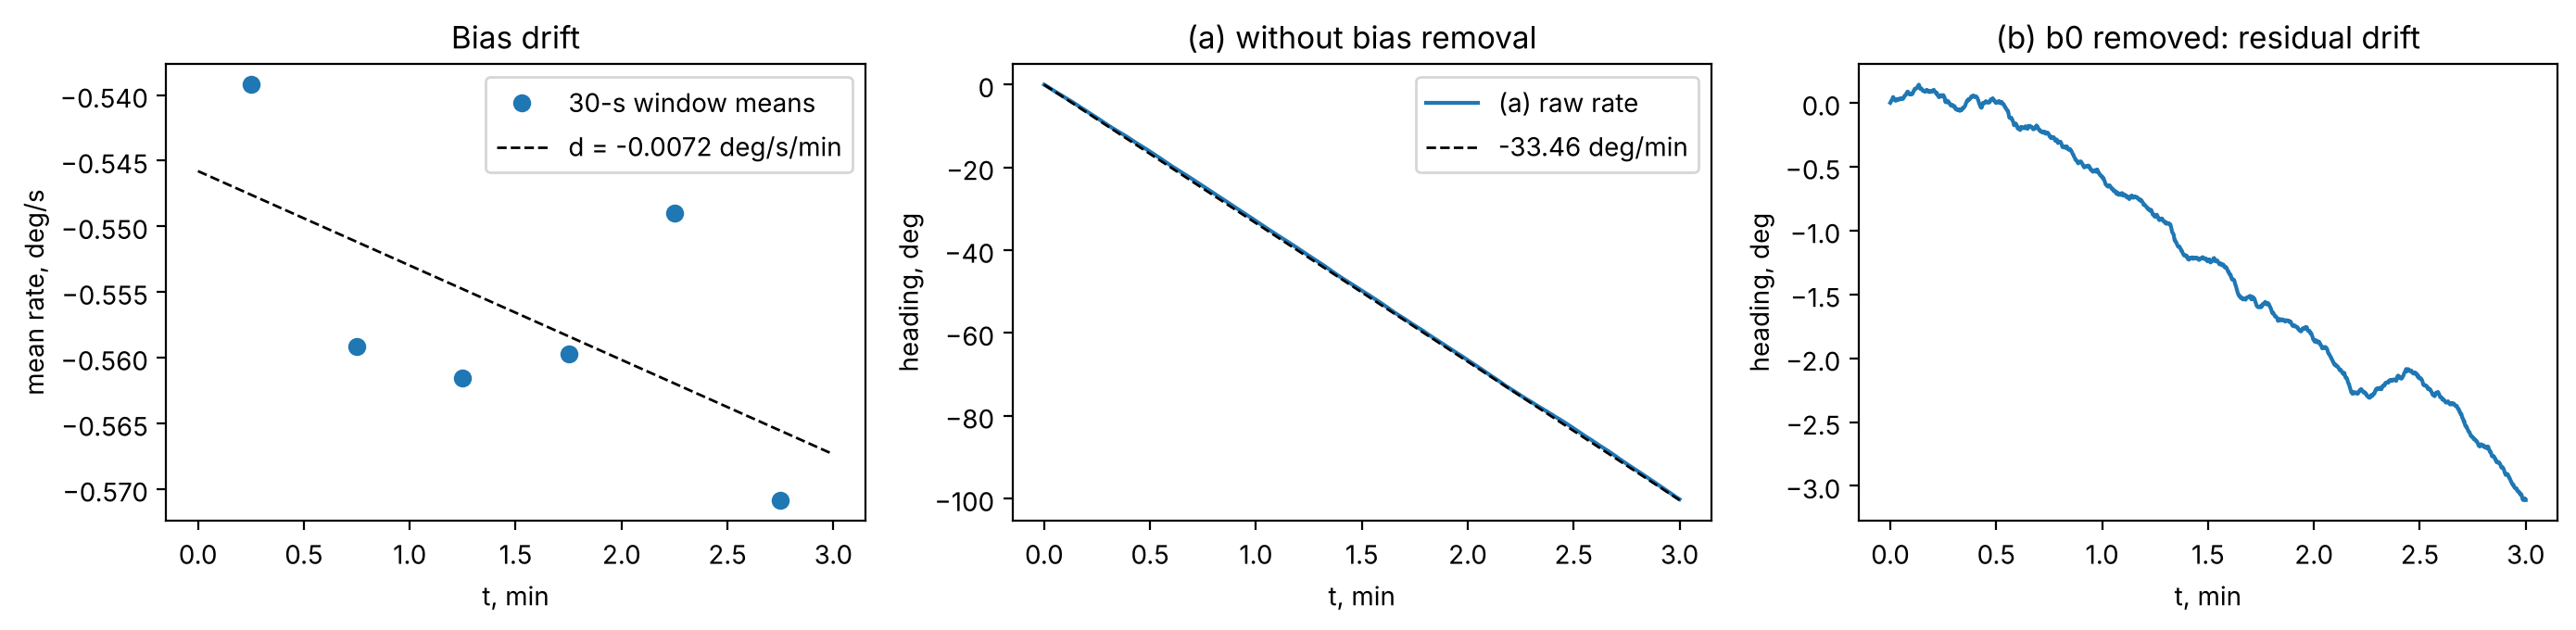

In [6]:
edges = np.arange(0, 180 + 1, 30)
centers = (edges[:-1] + edges[1:]) / 2 / 60                      # min
means = np.array([ws[(ts >= a) & (ts < a + 30)].mean() for a in edges[:-1]])
d, b_line = np.polyfit(centers, means, 1)                        # deg/s per min, deg/s
print(f'd = {d:+.4f} deg/s/min')

th_a = th_raw                                                    # (a) raw rate
th_b = cumulative_trapezoid(ws - b0, ts, initial=0)              # (b) rate minus b0
slope_a = np.polyfit(ts / 60, th_a, 1)[0]                        # deg/min
print(f'(a) uncorrected heading drift: {slope_a:.2f} deg/min;  b0·60 = {60 * b0:.2f} deg/min')
for m in [1, 2, 3]:
    print(f'(b) heading error after {m} min with b0 removed: {np.interp(60 * m, ts, th_b):+.2f} deg')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(centers, means, 'o', label='30-s window means')
cc = np.array([0, 3]); ax[0].plot(cc, d * cc + b_line, 'k--', lw=1, label=f'd = {d:+.4f} deg/s/min')
ax[0].set(xlabel='t, min', ylabel='mean rate, deg/s', title='Bias drift'); ax[0].legend()
ax[1].plot(ts / 60, th_a, label='(a) raw rate')
ax[1].plot(ts / 60, slope_a * ts / 60, 'k--', lw=1, label=f'{slope_a:.2f} deg/min')
ax[1].set(xlabel='t, min', ylabel='heading, deg', title='(a) without bias removal'); ax[1].legend()
ax[2].plot(ts / 60, th_b)
ax[2].set(xlabel='t, min', ylabel='heading, deg', title='(b) b0 removed: residual drift')
plt.tight_layout(); plt.show()

## 3. Measurement range $\omega_{max}$

At A = 150 % the motor power is clipped to ±100 % and the robot turns at its fastest. Where the gyro stops following the encoders, it is saturated.

+w_max = 286.5 deg/s (112 clipped samples)
-w_max = -286.7 deg/s (114 clipped samples)
fastest gyro rate 287 / -287 deg/s, fastest encoder rate 392 / -395 deg/s


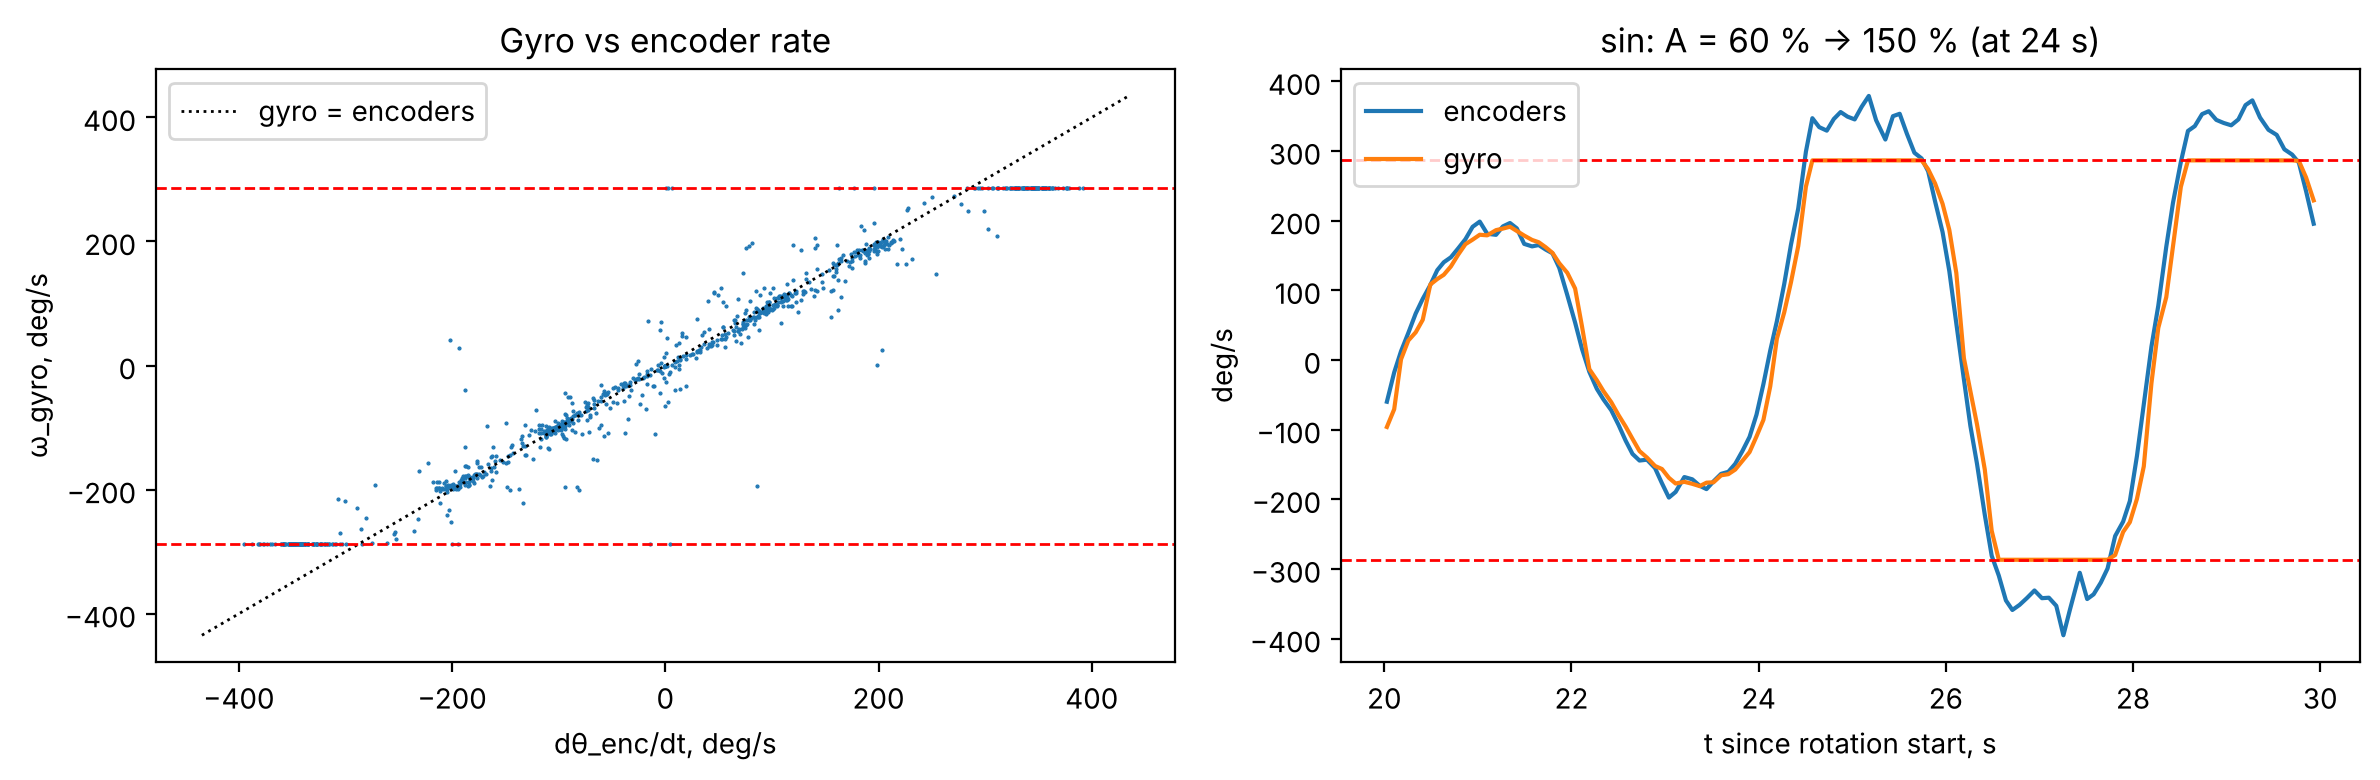

In [7]:
clip_w = sorted([SIGN * F * CLIP_HI, SIGN * F * CLIP_LO])          # deg/s (±inf if never clipped)
w_neg, w_pos = clip_w
print(f'+w_max = {w_pos:.1f} deg/s ({np.sum(rot & clipped & (w > 0))} clipped samples)')
print(f'-w_max = {w_neg:.1f} deg/s ({np.sum(rot & clipped & (w < 0))} clipped samples)')
print(f'fastest gyro rate {w[rot].max():.0f} / {w[rot].min():.0f} deg/s, fastest encoder rate {w_enc[rot].max():.0f} / {w_enc[rot].min():.0f} deg/s')
if not np.isfinite(w_pos) or not np.isfinite(w_neg):
    print('2D model: the simulated gyro has no measurement limit.' if SIM else
          'WARNING: no saturation in one direction: the robot did not reach the limit, spin it by hand faster.')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(w_enc[rot], w[rot], '.', ms=1)
lim = 1.1 * np.abs(w_enc[rot]).max(); ax[0].plot([-lim, lim], [-lim, lim], 'k:', lw=1, label='gyro = encoders')
for v in (w_pos, w_neg):
    if np.isfinite(v): ax[0].axhline(v, color='r', ls='--', lw=1)
ax[0].set(xlabel='dθ_enc/dt, deg/s', ylabel='ω_gyro, deg/s', title='Gyro vs encoder rate'); ax[0].legend()
t_rot0 = t[rot][0]; zoom = rot & (t > t_rot0 + 20) & (t < t_rot0 + 30)
ax[1].plot(t[zoom] - t_rot0, w_enc[zoom], label='encoders')
ax[1].plot(t[zoom] - t_rot0, w[zoom], label='gyro')
for v in (w_pos, w_neg):
    if np.isfinite(v): ax[1].axhline(v, color='r', ls='--', lw=1)
ax[1].set(xlabel='t since rotation start, s', ylabel='deg/s', title='sin: A = 60 % → 150 % (at 24 s)'); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Resolution $\Delta$

Distinct raw values in the static log, smallest non-zero difference, times F.

In [8]:
vals = np.unique(raw[static])
if len(vals) < 2:                                    # ideal gyro (2D model): constant while still
    vals = np.unique(raw)
d_raw = np.diff(vals).min()
delta = d_raw * F
print(f'{len(vals)} distinct raw values while still, e.g. {vals[:8].astype(int)}')
print(f'smallest step = {d_raw:.0f} raw unit  ->  Δ = {delta:.5f} deg/s = {1000 * delta:.2f} mdeg/s')

53 distinct raw values while still, e.g. [35 36 39 40 41 42 43 44]
smallest step = 1 raw unit  ->  Δ = 0.00875 deg/s = 8.75 mdeg/s


## 5. Noise $\sigma$

Static log (3 min), $b_0$ subtracted. σ is the measurement noise **R** for Lab 12 (at this sample rate).

sigma = 0.0709 deg/s  (gyro sample period 73.0 ms, N = 2312)
within ±1/2/3 sigma: 65.9 / 94.9 / 99.70 %   (Gaussian: 68.3 / 95.4 / 99.73 %)
skewness +0.09, excess kurtosis -0.05  (Gaussian: 0, 0)
outliers beyond 4 sigma: 0


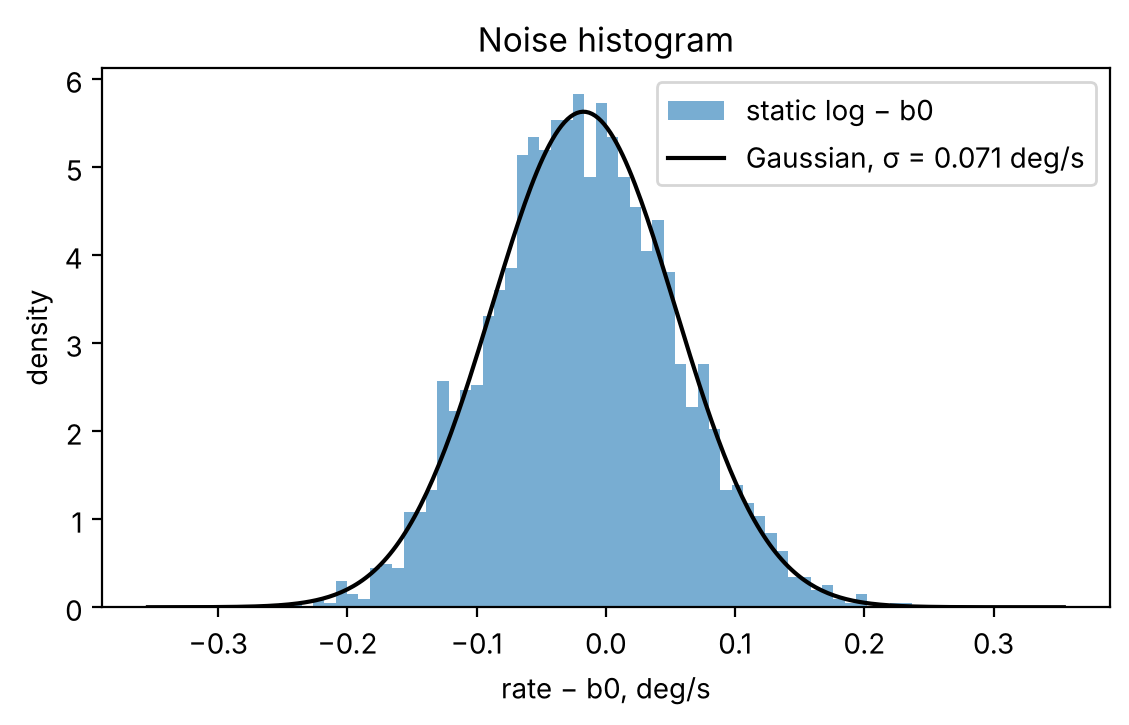

In [9]:
noise = ws - b0
sigma = noise.std()
print(f'sigma = {sigma:.4f} deg/s  (gyro sample period {1000 * Ts:.1f} ms, N = {len(noise)})')
if sigma > 0:
    z = noise / sigma
    within = [100 * np.mean(np.abs(z) < k) for k in (1, 2, 3)]
    print(f'within ±1/2/3 sigma: {within[0]:.1f} / {within[1]:.1f} / {within[2]:.2f} %   (Gaussian: 68.3 / 95.4 / 99.73 %)')
    print(f'skewness {stats.skew(noise):+.2f}, excess kurtosis {stats.kurtosis(noise):+.2f}  (Gaussian: 0, 0)')
    print(f'outliers beyond 4 sigma: {np.sum(np.abs(z) > 4)}')
else:
    print('no noise at all: ideal gyro (2D model)')

k = np.round(ws / delta)
bins = (np.arange(k.min() - 1, k.max() + 2) - 0.5) * delta - b0   # one bin per raw step
plt.figure(figsize=(6.5, 3.5))
plt.hist(noise, bins=bins, density=True, alpha=0.6, label='static log − b0')
if sigma > 0:
    xx = np.linspace(-5 * sigma, 5 * sigma, 300)
    plt.plot(xx, stats.norm.pdf(xx, noise.mean(), sigma), 'k', label=f'Gaussian, σ = {sigma:.3f} deg/s')
plt.xlabel('rate − b0, deg/s'); plt.ylabel('density'); plt.title('Noise histogram'); plt.legend(); plt.show()

## 6. Scale factor $s$

$\theta_{gyro}(t) = \int(\omega - b_0)\,dt$ (with `calibrate_gyro`), $\theta_{enc}$ from the wheels, both from 0 at the start of the rotation.
The rotation is cut into single turns using the encoder rate: a turn runs from one stop (or reversal) to the next, so both sensors are compared where the robot is not moving and a small time lag between them does not matter. For each turn, $\Delta\theta_{gyro}$ is compared with $\Delta\theta_{enc}$; the slope through the origin is $1+s$, fitted for CCW and CW separately.
Turns where the gyro clipped belong to §3, not to $s$, so they are left out of the fit.

s_CCW = -3.31 %   (12 unsaturated turns)
s_CW = -4.48 %   (12 unsaturated turns)

s per amplitude, %, unsaturated turns only:


dir,CCW,CW
block,,
sin 30,-2.25,-2.07
sin 60,-2.45,-3.02
rect 30,-2.17,-2.94
rect 60,-4.24,-6.02


saturated turns: 11 of 35 (all at A = 150 %: {'rect 150', 'sin 150'})


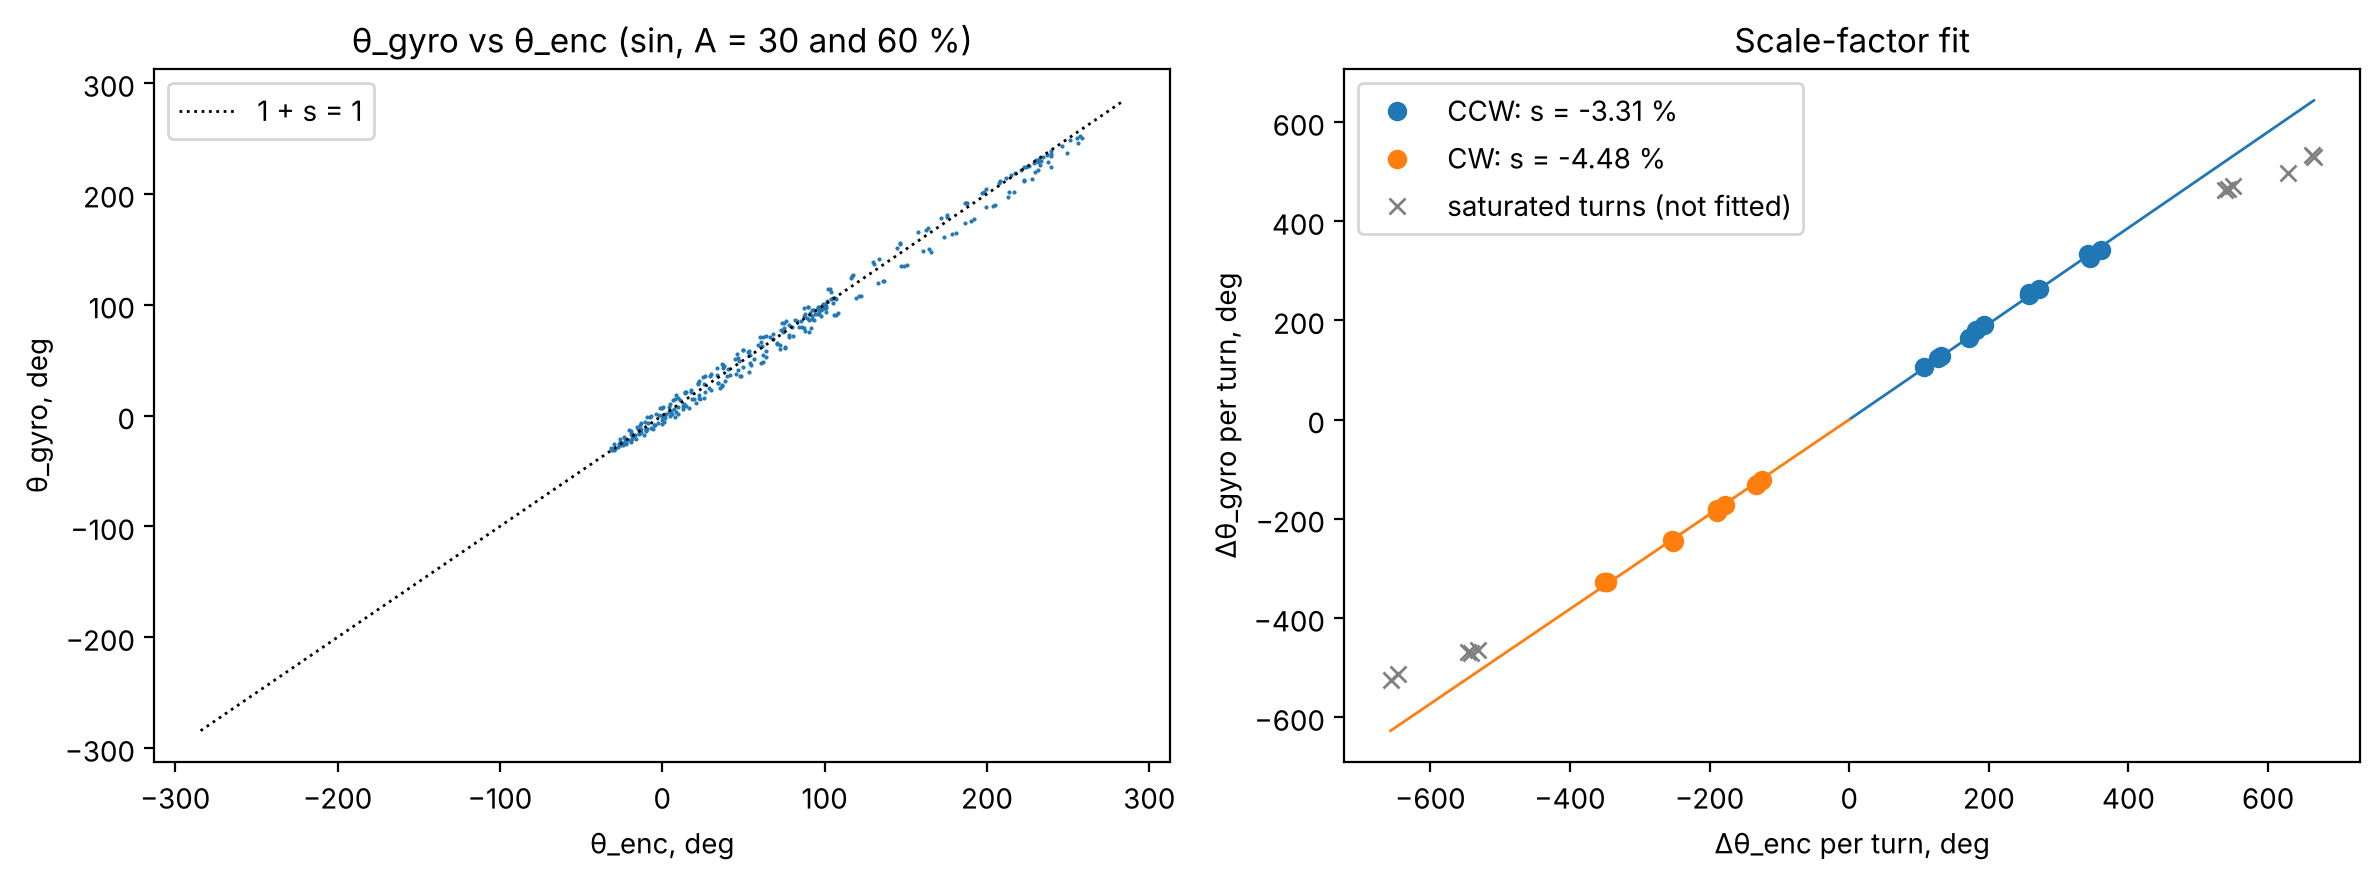

In [10]:
i_rot = np.where(rot)[0]
th_g = np.full_like(t, np.nan); th_e = np.full_like(t, np.nan)
th_g[rot] = cumulative_trapezoid(w[rot] - b_cal, t_g[rot], initial=0)
th_e[rot] = th_enc[rot] - th_enc[rot][0]

t_start = {p: t[phase == p][0] for p in ['sin', 'rect', 'rest']}
def block(i):                                        # 'sin 30', ..., 'rect 150', 'rest'
    if phase[i] == 'rest': return 'rest'
    tau = t[i] - t_start[phase[i]]
    return f'{phase[i]} {AMP[min(int(tau // 12), 2)]}'

dirn = np.where(w_enc > 5, 1, np.where(w_enc < -5, -1, 0))    # moving CCW / CW / still
runs, i = [], i_rot[0]
while i <= i_rot[-1]:                                          # runs of constant direction
    if dirn[i] == 0: i += 1; continue
    j = i
    while j + 1 <= i_rot[-1] and dirn[j + 1] == dirn[i]: j += 1
    runs.append([i, j, dirn[i]]); i = j + 1
for k in range(len(runs) - 1):                                 # a turn ends where the robot stops or reverses:
    b = (runs[k][1] + runs[k + 1][0]) // 2                     # cut in the middle of the still gap
    runs[k][1], runs[k + 1][0] = b, b
runs[0][0], runs[-1][1] = i_rot[0], i_rot[-1]
turns = pd.DataFrame([dict(i0=i, i1=j, dir='CCW' if dr > 0 else 'CW', block=block((i + j) // 2),
                           d_enc=th_e[j] - th_e[i], d_gyro=th_g[j] - th_g[i], sat=bool(np.any(clipped[i:j + 1])))
                      for i, j, dr in runs])
turns = turns[(turns.block != 'rest') & (turns.d_enc.abs() > 5)].reset_index(drop=True)

s_est = {}
for D in ['CCW', 'CW']:
    g = turns[(turns.dir == D) & ~turns.sat]
    s_est[D] = (g.d_gyro * g.d_enc).sum() / (g.d_enc ** 2).sum() - 1
    print(f's_{D} = {100 * s_est[D]:+.2f} %   ({len(g)} unsaturated turns)')

turns['s_%'] = 100 * (turns.d_gyro / turns.d_enc - 1)
by_amp = (turns[~turns.sat].groupby(['block', 'dir'], sort=False)
          .apply(lambda g: 100 * ((g.d_gyro * g.d_enc).sum() / (g.d_enc ** 2).sum() - 1), include_groups=False)
          .unstack().round(2))
print('\ns per amplitude, %, unsaturated turns only:'); display(by_amp)
print(f'saturated turns: {turns.sat.sum()} of {len(turns)} (all at A = 150 %: {set(turns[turns.sat].block)})')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
early = rot & (t < t[rot][0] + 24)                   # sin, A = 30 and 60 %: no saturation
ax[0].plot(th_e[early], th_g[early], '.', ms=1)
lim = np.nanmax(np.abs(th_e[early])) * 1.1; ax[0].plot([-lim, lim], [-lim, lim], 'k:', lw=1, label='1 + s = 1')
ax[0].set(xlabel='θ_enc, deg', ylabel='θ_gyro, deg', title='θ_gyro vs θ_enc (sin, A = 30 and 60 %)'); ax[0].legend()
for D, c in [('CCW', 'C0'), ('CW', 'C1')]:
    g = turns[turns.dir == D]
    ax[1].plot(g.d_enc[~g.sat], g.d_gyro[~g.sat], 'o', color=c, label=f'{D}: s = {100 * s_est[D]:+.2f} %')
    ax[1].plot(g.d_enc[g.sat], g.d_gyro[g.sat], 'x', color='grey')
    xx = np.array([0, g.d_enc.abs().max() * np.sign(g.d_enc.iloc[0])])
    ax[1].plot(xx, (1 + s_est[D]) * xx, color=c, lw=1)
ax[1].plot([], [], 'x', color='grey', label='saturated turns (not fitted)')
ax[1].set(xlabel='Δθ_enc per turn, deg', ylabel='Δθ_gyro per turn, deg', title='Scale-factor fit'); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Rotation run: gyro vs encoders (Lab execution, Step 3)

Heading from both sensors and the error $e(t) = \theta_{gyro} - \theta_{enc}$; the table shows how much $e$ changes in each part of the run.

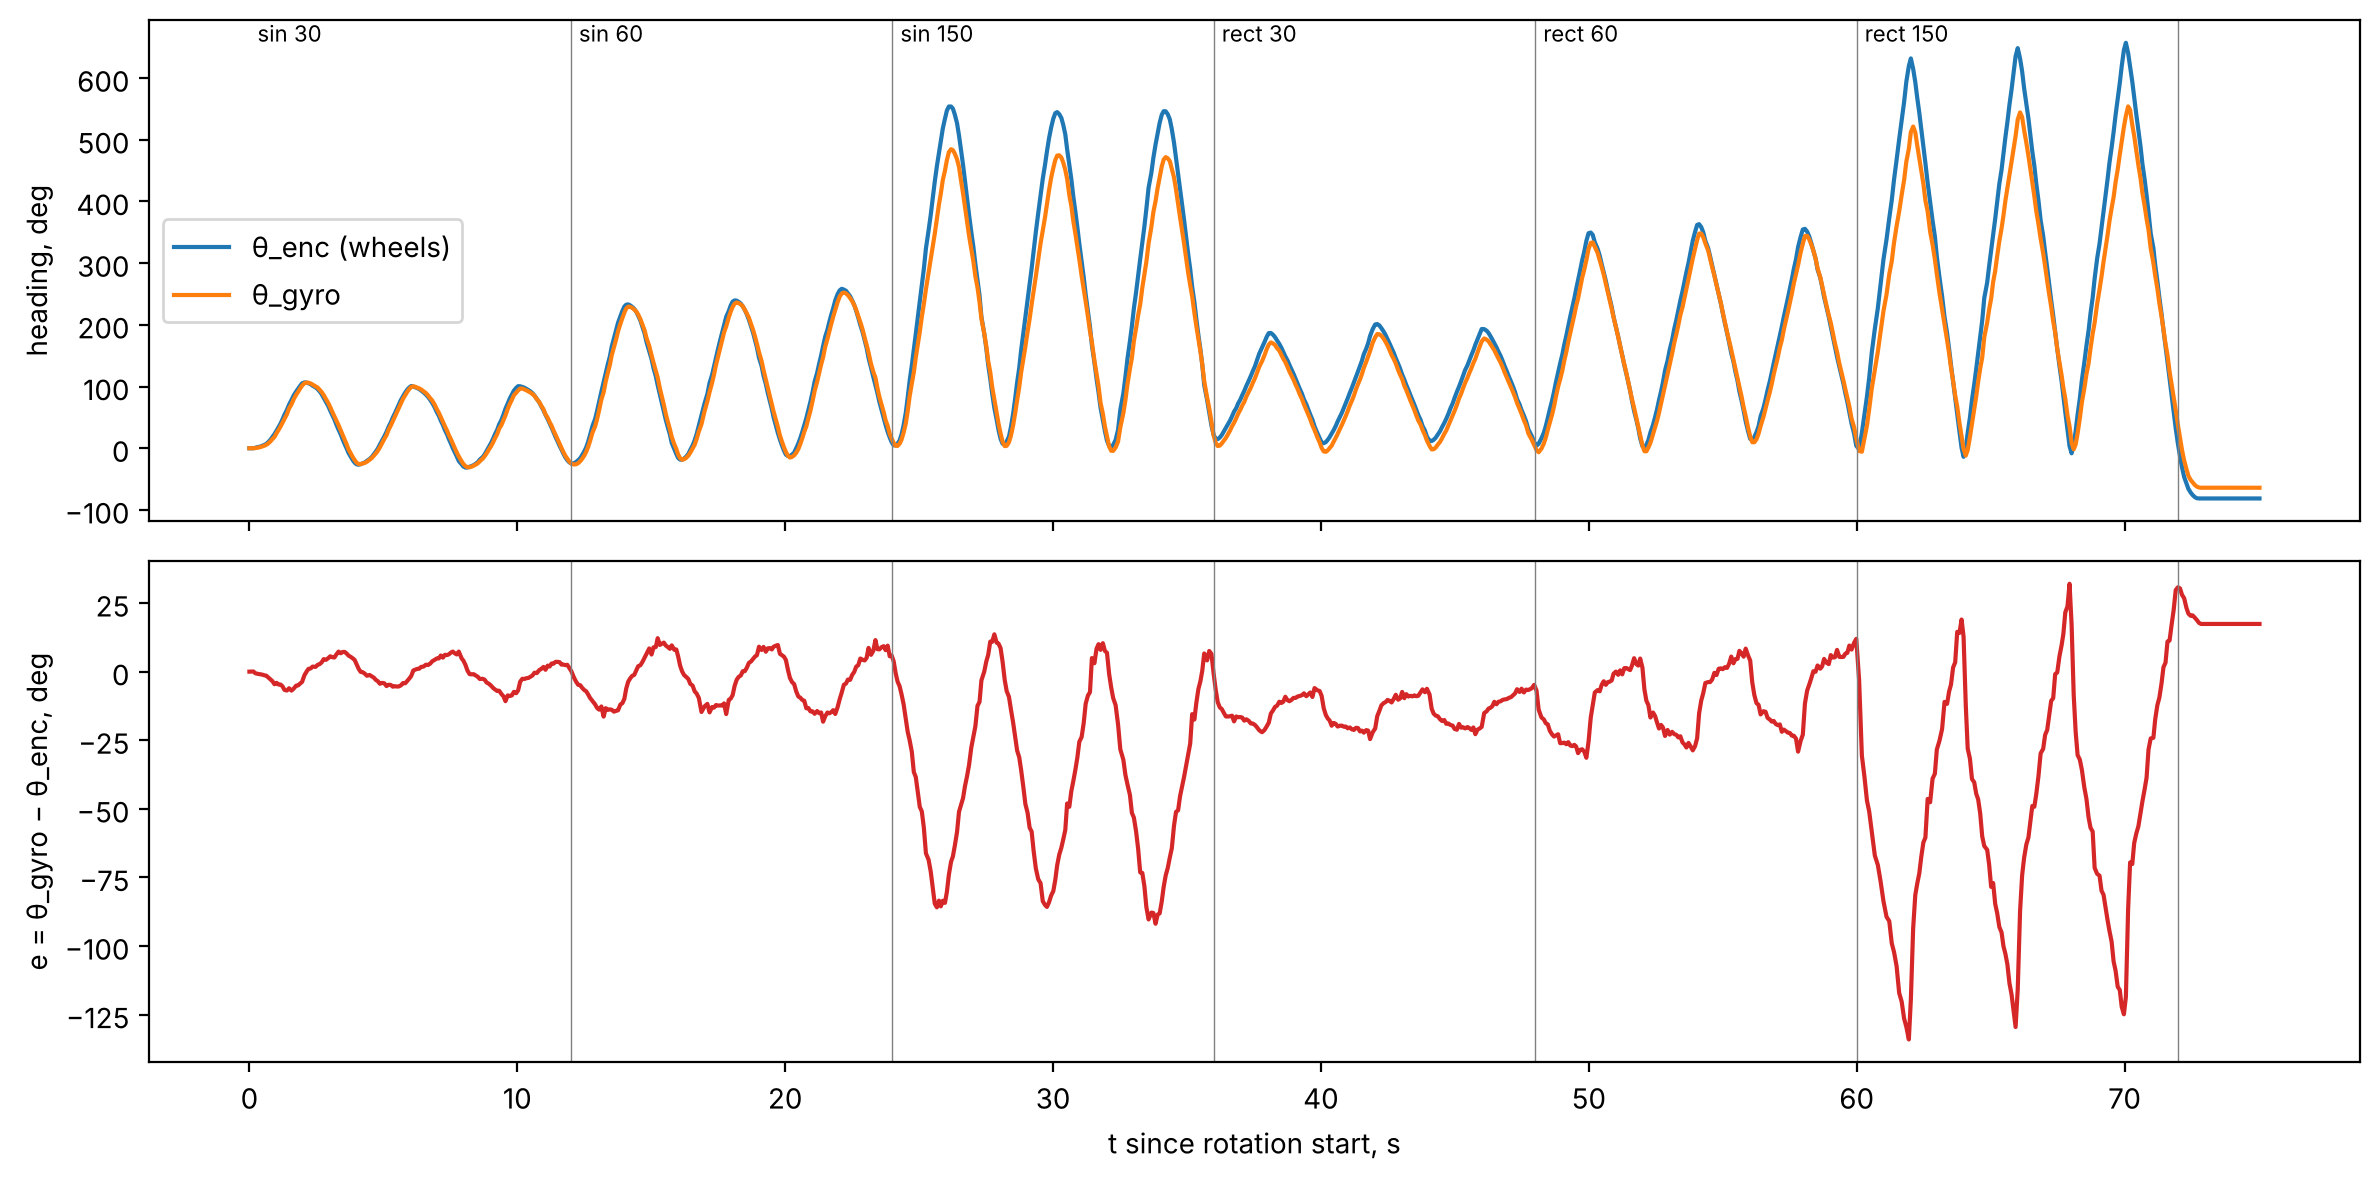

,"change of e, deg",clipped samples
part,,
sin 30,1.38,0
sin 60,5.74,0
sin 150,2.71,92
rect 30,-4.22,0
rect 60,18.82,0
rect 150,32.89,133
rest,-13.36,1


e swings by up to 43.3 deg within an A = 30/60 % part, up to 166.1 deg within an A = 150 % part
e at the end: +17.4 deg;  saturated turns lose 100 deg each on average
Final heading: θ_enc = -81.4 deg, θ_gyro = -64.0 deg
Slip check: set TAPE_DEG (protractor angle to the tape mark) in the first cell.


In [11]:
e = th_g - th_e
tt = t - t[rot][0]
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(tt[rot], th_e[rot], label='θ_enc (wheels)')
ax[0].plot(tt[rot], th_g[rot], label='θ_gyro')
ax[0].set(ylabel='heading, deg'); ax[0].legend()
ax[1].plot(tt[rot], e[rot], color='C3')
ax[1].set(xlabel='t since rotation start, s', ylabel='e = θ_gyro − θ_enc, deg')
for x in [12, 24, 36, 48, 60, 72]:
    for a in ax: a.axvline(x, color='grey', lw=0.5)
for k, x in enumerate(range(0, 72, 12)):
    ax[0].text(x + 0.3, ax[0].get_ylim()[1], ['sin 30', 'sin 60', 'sin 150', 'rect 30', 'rect 60', 'rect 150'][k], va='top', fontsize=8)
plt.tight_layout(); plt.show()

blk = np.array([block(i) if rot[i] else '' for i in range(len(t))])
rows = []
for b in ['sin 30', 'sin 60', 'sin 150', 'rect 30', 'rect 60', 'rect 150', 'rest']:
    idx = np.where(blk == b)[0]
    if len(idx): rows.append((b, e[idx[-1]] - e[idx[0]], np.sum(clipped[idx])))
de = pd.DataFrame(rows, columns=['part', 'change of e, deg', 'clipped samples']).set_index('part').round(2)
display(de)
E_END = e[i_rot[-1]]
swing = lambda names: max(np.ptp(e[blk == b]) for b in names)     # largest change of e within one part
E_UNSAT, E_SAT = swing(['sin 30', 'sin 60', 'rect 30', 'rect 60']), swing(['sin 150', 'rect 150'])
print(f'e swings by up to {E_UNSAT:.1f} deg within an A = 30/60 % part, up to {E_SAT:.1f} deg within an A = 150 % part')
sat_loss = (turns[turns.sat].d_gyro - turns[turns.sat].d_enc).abs()
SAT_LOSS = sat_loss.mean() if len(sat_loss) else 0.0
print(f'e at the end: {E_END:+.1f} deg;  saturated turns lose {SAT_LOSS:.0f} deg each on average')
print(f'Final heading: θ_enc = {th_e[i_rot[-1]]:+.1f} deg, θ_gyro = {th_g[i_rot[-1]]:+.1f} deg')
if TAPE_DEG is None:
    print('Slip check: set TAPE_DEG (protractor angle to the tape mark) in the first cell.')
else:
    off = lambda th: (th - TAPE_DEG + 180) % 360 - 180          # protractor only sees the angle modulo 360
    oe, og = off(th_e[i_rot[-1]]), off(th_g[i_rot[-1]])
    better = 'encoders' if abs(oe) < abs(og) else 'gyro'
    print(f'Slip check: tape {TAPE_DEG:+.1f} deg -> encoders off by {oe:+.1f}, gyro off by {og:+.1f}: '
          f'the {better} {"are" if better == "encoders" else "is"} closer to the truth.')

## 8. Simulated gyro `gyro_sim(omega_true, t)`

The model from the top of the notebook with the identified parameters ($s$ is taken per direction). $t$ is the time since the static log started (the bias drifts with it).
Test: feed it the encoder rate of the recorded rotation and overlay its output on the real gyro.

rate RMS (sim − real gyro): 34.7 deg/s
heading RMS from the real gyro: gyro_sim 29.8 deg,  ideal gyro (= encoders) 34.7 deg


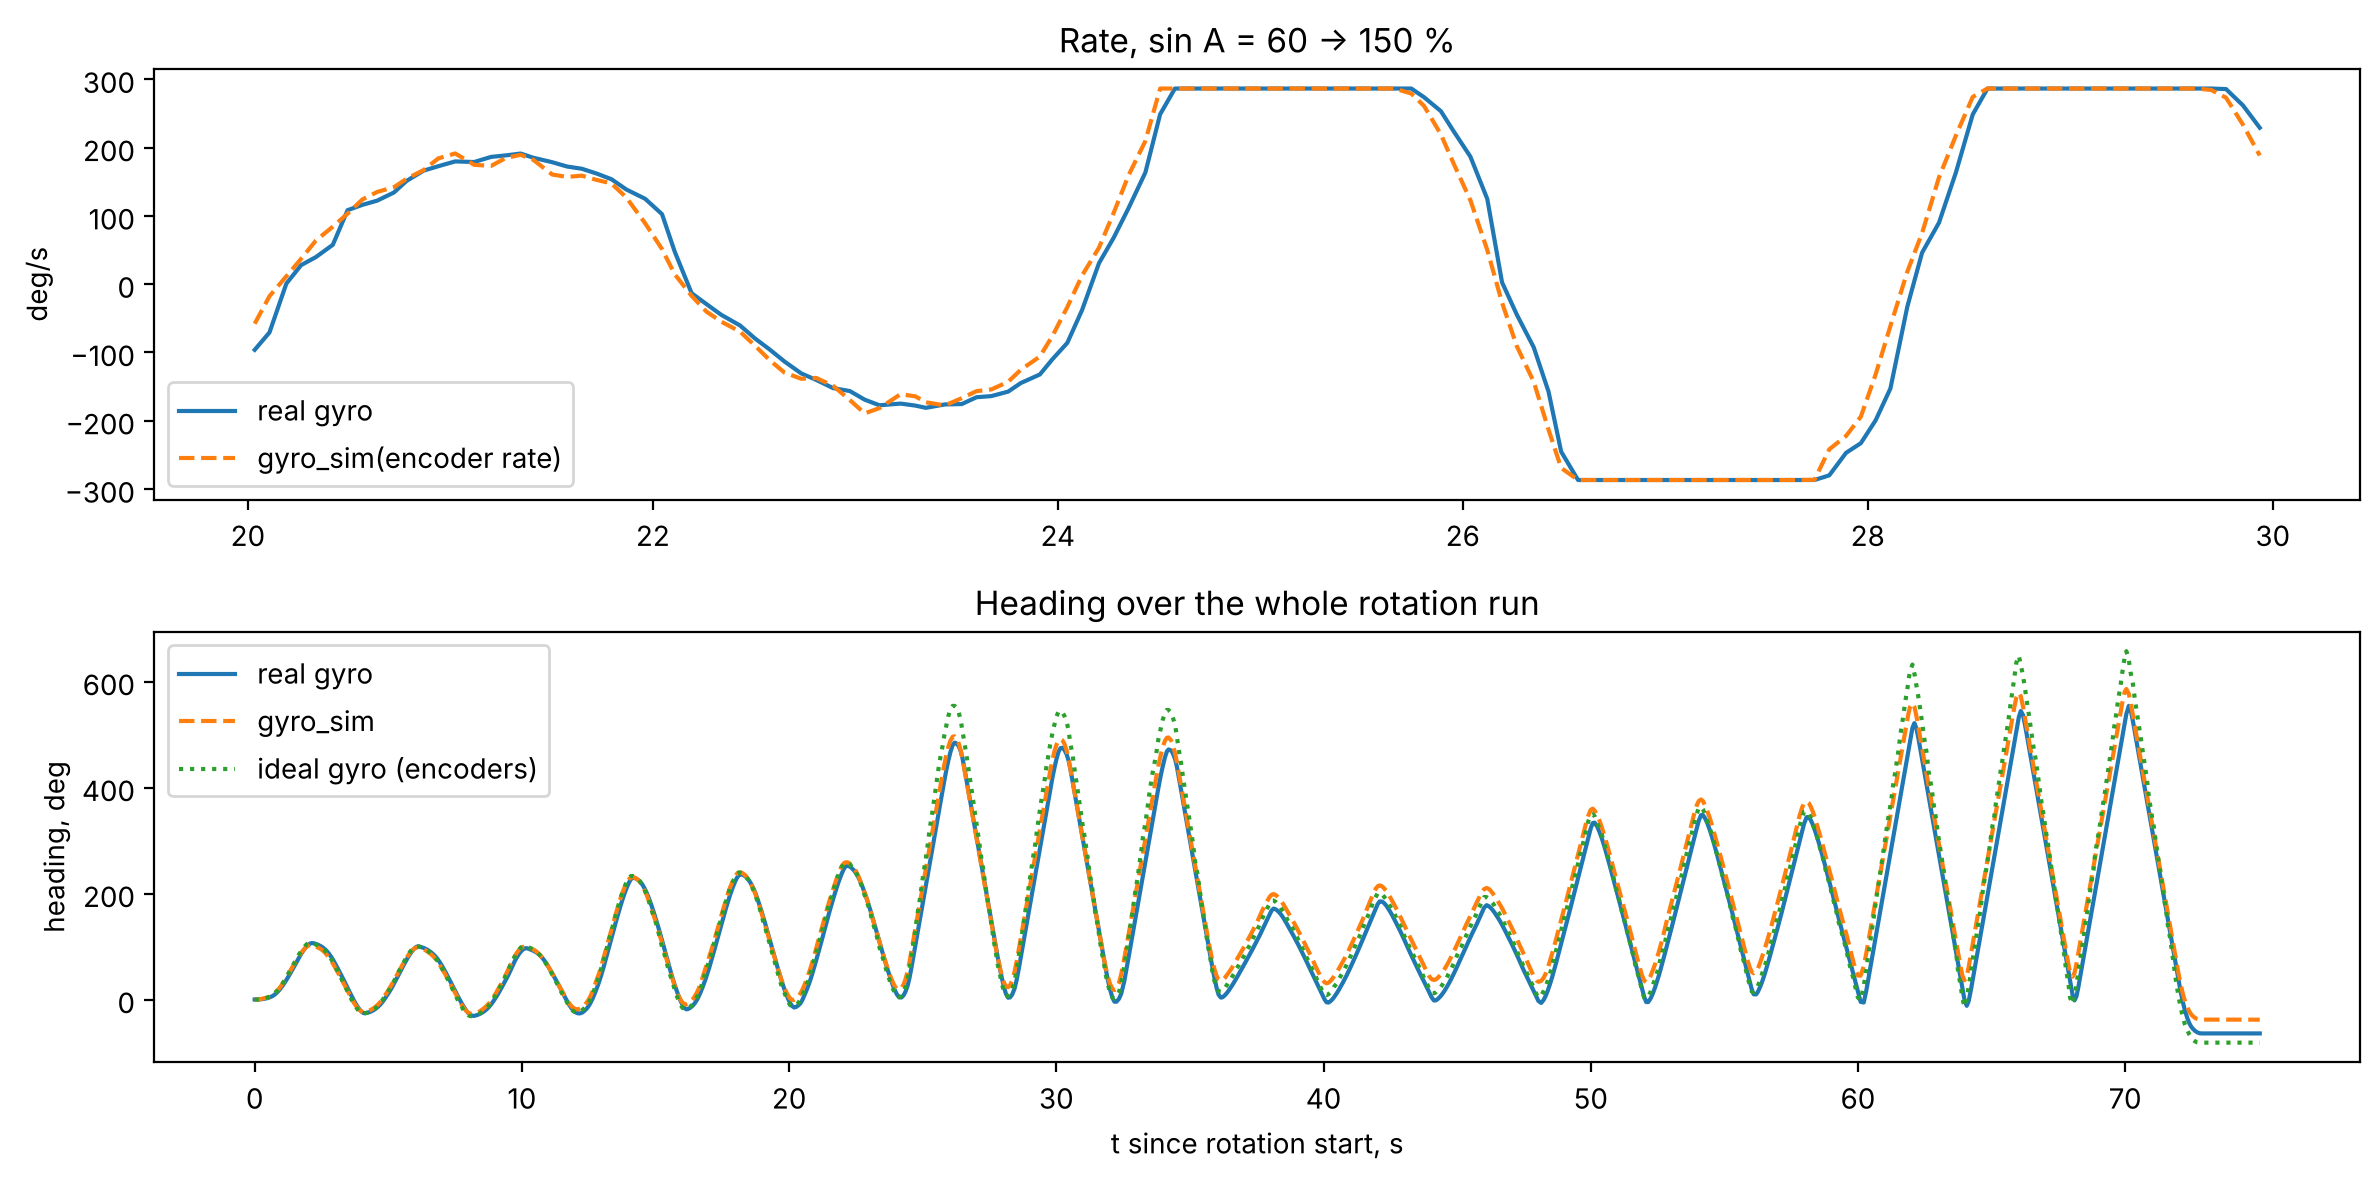

In [12]:
P = dict(b0=b0, d=d, wmax_pos=w_pos, wmax_neg=w_neg, delta=delta, sigma=sigma, s_ccw=s_est['CCW'], s_cw=s_est['CW'])

def gyro_sim(omega_true, t, p=P, seed=0):
    # simulated TRIK gyro: omega_true in deg/s (CCW +), t in s -> measured rate, deg/s
    rng = np.random.default_rng(seed)
    omega_true = np.asarray(omega_true, float)
    s = np.where(omega_true >= 0, p['s_ccw'], p['s_cw'])
    w_m = (1 + s) * omega_true + p['b0'] + p['d'] * np.asarray(t) / 60 + rng.normal(0, p['sigma'], omega_true.shape)
    w_m = np.clip(w_m, p['wmax_neg'], p['wmax_pos'])               # saturation
    return p['delta'] * np.round(w_m / p['delta'])                 # quantisation

idx = rot & new
w_sim = gyro_sim(w_enc[idx], t_g[idx])
tr = t_g[idx] - t_g[idx][0]
th_sim = cumulative_trapezoid(w_sim - b_cal, tr, initial=0)
th_real = cumulative_trapezoid(w[idx] - b_cal, tr, initial=0)
th_ideal = th_enc[idx] - th_enc[idx][0]
rms = lambda x: np.sqrt(np.mean(x ** 2))
print(f'rate RMS (sim − real gyro): {rms(w_sim - w[idx]):.1f} deg/s')
print(f'heading RMS from the real gyro: gyro_sim {rms(th_sim - th_real):.1f} deg,  ideal gyro (= encoders) {rms(th_ideal - th_real):.1f} deg')

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
z = (tr > 20) & (tr < 30)
ax[0].plot(tr[z], w[idx][z], label='real gyro')
ax[0].plot(tr[z], w_sim[z], '--', label='gyro_sim(encoder rate)')
ax[0].set(ylabel='deg/s', title='Rate, sin A = 60 → 150 %'); ax[0].legend()
ax[1].plot(tr, th_real, label='real gyro')
ax[1].plot(tr, th_sim, '--', label='gyro_sim')
ax[1].plot(tr, th_ideal, ':', label='ideal gyro (encoders)')
ax[1].set(xlabel='t since rotation start, s', ylabel='heading, deg', title='Heading over the whole rotation run'); ax[1].legend()
plt.tight_layout(); plt.show()

## 9. Parameter table

In [13]:
tab = f'''| Parameter | Symbol | Value | Unit | Method |
|---|---|---|---|---|
| Offset (bias) | $b_0$ | {b0:.4f} ± {se:.4f} | deg/s | static mean, T = 30 s |
| Bias drift | $d$ | {d:+.4f} | deg/s/min | 30-s window means |
| Heading drift, uncorrected | | {slope_a:.2f} | deg/min | slope of θ(t) |
| Measurement range | ±$\\omega_{{max}}$ | +{w_pos:.1f} / {w_neg:.1f} | deg/s | saturation test, sin/rect at A = 150 % |
| Resolution | $\\Delta$ | {delta:.5f} | deg/s | quantisation step (1 raw unit) |
| Noise std | $\\sigma$ | {sigma:.4f} | deg/s | static, 3 min |
| Raw → deg/s factor | F | {F:.6f} | deg/s per raw unit | `read()[2]` vs `readRawData()[2]` |
| Scale-factor error CCW / CW | $s$ | {100 * s_est['CCW']:+.2f} / {100 * s_est['CW']:+.2f} | % | gyro vs. encoder angle, unsaturated turns |
| Positive rotation direction | | {POS_DIR} | — | gyro vs. encoder sign |

`calibrate_gyro`: T_CAL = {T_CAL} s, b0 = {b_cal:.4f} deg/s. Slip check (tape): {"not entered" if TAPE_DEG is None else f"{TAPE_DEG:+.1f} deg"}.'''
display(Markdown(tab))

| Parameter | Symbol | Value | Unit | Method |
|---|---|---|---|---|
| Offset (bias) | $b_0$ | -0.5392 ± 0.0035 | deg/s | static mean, T = 30 s |
| Bias drift | $d$ | -0.0072 | deg/s/min | 30-s window means |
| Heading drift, uncorrected | | -33.46 | deg/min | slope of θ(t) |
| Measurement range | ±$\omega_{max}$ | +286.5 / -286.7 | deg/s | saturation test, sin/rect at A = 150 % |
| Resolution | $\Delta$ | 0.00875 | deg/s | quantisation step (1 raw unit) |
| Noise std | $\sigma$ | 0.0709 | deg/s | static, 3 min |
| Raw → deg/s factor | F | 0.008752 | deg/s per raw unit | `read()[2]` vs `readRawData()[2]` |
| Scale-factor error CCW / CW | $s$ | -3.31 / -4.48 | % | gyro vs. encoder angle, unsaturated turns |
| Positive rotation direction | | CW | — | gyro vs. encoder sign |

`calibrate_gyro`: T_CAL = 30 s, b0 = -0.5392 deg/s. Slip check (tape): not entered.

## 10. Short analysis

In [14]:
times = {'10 s': 10, '1 min': 60, '3 min': 180}
cal_err = abs(b_line - b_cal)                        # calibration error vs the bias line at t = 0, deg/s
budget = pd.DataFrame({k: {'offset b0, not removed': abs(b0) * x,
                           'offset left after calibrate_gyro': cal_err * x,
                           'bias drift d': 0.5 * abs(d) / 60 * x ** 2,
                           'noise σ (1σ random walk)': sigma * np.sqrt(x * Ts),
                           'measured on the static log, after calibrate_gyro': abs(np.interp(x, ts, th_c))}
                       for k, x in times.items()}).round(2)
display(budget.rename(columns=lambda c: c + ', deg'))
after = budget.iloc[1:4]
dom = {k: after[k].idxmax() for k in times}

cal_why = (f'At {T_CAL} s the estimate is within ±0.005 deg/s (±2 SE) and $b_0(T)$ is flat from there on, so a longer calibration only costs time.'
           if FLAT else f'With one sample every {1000 * Ts:.0f} ms, the noise alone needs about {(2 * sigma / TOL) ** 2 * Ts:.0f} s of averaging to pin $b_0$ down to ±0.005 deg/s, and $b_0(T)$ still moves by a few hundredths of a deg/s within 30 s, so the full 30 s is used: a longer calibration would help only a little, a shorter one clearly less.')
s_sin = np.nanmean(by_amp.loc[[b for b in by_amp.index if b.startswith('sin')]].values)
s_rect = np.nanmean(by_amp.loc[[b for b in by_amp.index if b.startswith('rect')]].values)
slip_txt = (f'Square-wave turns give a more negative s than sine turns ({s_rect:+.1f} % vs {s_sin:+.1f} %): at the hard reversals the wheels slip, so the encoders over-count the turn and θ_enc is the less reliable reference there.'
            if s_rect < s_sin - 1 else
            f's is about the same for sine and square-wave turns ({s_sin:+.1f} % vs {s_rect:+.1f} %), so wheel slip at the reversals does not show separately (it may be hidden inside s).')
SF_TURN = 360 * max(abs(s_est['CCW']), abs(s_est['CW']))      # deg per full turn
cmp_sf = ('more than all the time-dependent errors after 1 min' if SF_TURN > after['1 min'].max()
          else 'less than the time-dependent errors after 1 min')
sat_txt = (f"and every turn faster than ±{w_pos:.0f} deg/s loses on average {SAT_LOSS:.0f}° to saturation"
           + (', the largest error of all.' if SAT_LOSS > SF_TURN else '.')) if SAT_LOSS else 'and no turn reached saturation.'
display(Markdown(f'''
**Which error source dominates.** Without calibration the offset dominates at every time. Its error grows linearly:
{budget.iloc[0, 0]:.1f}° after 10 s, {budget.iloc[0, 1]:.1f}° after 1 min, {budget.iloc[0, 2]:.1f}° after 3 min ({slope_a:.1f} deg/min).
After `calibrate_gyro`, the largest term is the **{dom['10 s']}** after 10 s, the **{dom['1 min']}** after 1 min
and the **{dom['3 min']}** after 3 min. Drift grows as t², noise only as √t (below {budget.iloc[3, 2]:.2f}° even after 3 min).
When the robot turns, the scale factor adds about {SF_TURN:.0f}° per full turn (s = {100 * s_est['CCW']:+.1f} % CCW, {100 * s_est['CW']:+.1f} % CW),
{cmp_sf}, {sat_txt}
On the rotation run e(t) swings by up to {E_UNSAT:.0f}° within an A = 30/60 % part (scale factor) and by up to {E_SAT:.0f}° within an A = 150 % part (saturation); at the end it is {E_END:+.0f}°.
{slip_txt}

**Calibration.** `calibrate_gyro` averages the first **{T_CAL} s** of the static log after removing spikes (more than 4 robust σ from the median).
{cal_why}
On the static log it leaves **{abs(th_c180):.2f}°** of heading error after 3 min, against {abs(np.interp(180, ts, th_raw)):.1f}° without calibration.
'''))

,"10 s, deg","1 min, deg","3 min, deg"
"offset b0, not removed",5.39,32.35,97.06
offset left after calibrate_gyro,0.07,0.40,1.19
bias drift d,0.01,0.22,1.94
noise σ (1σ random walk),0.06,0.15,0.26
"measured on the static log, after calibrate_gyro",0.09,0.58,3.11



**Which error source dominates.** Without calibration the offset dominates at every time. Its error grows linearly:
5.4° after 10 s, 32.4° after 1 min, 97.1° after 3 min (-33.5 deg/min).
After `calibrate_gyro`, the largest term is the **offset left after calibrate_gyro** after 10 s, the **offset left after calibrate_gyro** after 1 min
and the **bias drift d** after 3 min. Drift grows as t², noise only as √t (below 0.26° even after 3 min).
When the robot turns, the scale factor adds about 16° per full turn (s = -3.3 % CCW, -4.5 % CW),
more than all the time-dependent errors after 1 min, and every turn faster than ±287 deg/s loses on average 100° to saturation, the largest error of all.
On the rotation run e(t) swings by up to 43° within an A = 30/60 % part (scale factor) and by up to 166° within an A = 150 % part (saturation); at the end it is +17°.
Square-wave turns give a more negative s than sine turns (-3.8 % vs -2.4 %): at the hard reversals the wheels slip, so the encoders over-count the turn and θ_enc is the less reliable reference there.

**Calibration.** `calibrate_gyro` averages the first **30 s** of the static log after removing spikes (more than 4 robust σ from the median).
With one sample every 73 ms, the noise alone needs about 59 s of averaging to pin $b_0$ down to ±0.005 deg/s, and $b_0(T)$ still moves by a few hundredths of a deg/s within 30 s, so the full 30 s is used: a longer calibration would help only a little, a shorter one clearly less.
On the static log it leaves **3.11°** of heading error after 3 min, against 100.2° without calibration.


## 11. Second run: what repeats and what changes

The same experiment run again (`lab9_gyro_run2.csv`) and processed with the same methods. Parameters of the sensor itself (F, Δ, σ, ω_max, s) should repeat; the offset and its drift are different after every power-on, which is why `calibrate_gyro` must run at every start.

In [15]:
def key_params(path):
    # the table parameters of one log, with the same methods as sections 0-6
    g = pd.read_csv(path)
    g[num] = g[num].apply(pd.to_numeric, errors='coerce'); g = g.dropna().reset_index(drop=True)
    g['phase'] = g.phase.astype(str).str.strip().str.replace(r'\.0$', '', regex=True).replace(codes)
    tt = g.t_ms.to_numpy() / 1000
    tk = (np.diff(g.t_us.to_numpy(np.int64)) + 2**31) % 2**32 - 2**31
    tg = np.r_[0, np.cumsum(tk)] * UNIT * 1e-6
    ph = g.phase.to_numpy(); rr = g.gz_raw.to_numpy(float); cc = g.gz_cal.to_numpy(float)
    st, ro = ph == 'static', np.isin(ph, ['sin', 'rect', 'rest'])
    te = r / B * (g.encR - g.encL).to_numpy(float)
    win = 2 * max(1, round(0.05 / np.median(np.diff(tt)))) + 1
    we = np.gradient(pd.Series(te).rolling(win, center=True, min_periods=1).mean(), tt)
    clip_v = [v for v in (rr[ro].max(), rr[ro].min())
              if np.sum(ro & (rr == v)) >= 10 and (32700 <= abs(v) <= 32768 or np.median(np.abs(we[ro & (rr == v)])) > 1.1 * abs(v) * 0.00875)]
    cl = np.isin(rr, clip_v)
    ft = ro & ~cl
    p1 = np.polyfit(rr[ft], cc[ft], 1); res = cc - np.polyval(p1, rr)
    kp = ft & (np.abs(res) < 5 * 1.4826 * np.median(np.abs(res[ft])) + 10)
    Fg = np.polyfit(rr[kp], cc[kp], 1)[0] / 1000
    sg = 1 if np.corrcoef(rr[ro], we[ro])[0, 1] > 0 else -1
    wg = sg * Fg * rr
    t0s, ws_ = tg[st] - tg[st][0], wg[st]
    b0g = ws_[t0s < 30].mean()
    mm = [ws_[(t0s >= a) & (t0s < a + 30)].mean() for a in range(0, 180, 30)]
    dg = np.polyfit((np.arange(0, 180, 30) + 15) / 60, mm, 1)[0]
    vals = np.unique(rr[st]); dlt = np.diff(vals).min() * Fg
    # scale factor: turns from stop to stop, unsaturated only
    thg = cumulative_trapezoid(wg[ro] - b0g, tg[ro], initial=0); the = te[ro] - te[ro][0]
    dr = np.where(we[ro] > 5, 1, np.where(we[ro] < -5, -1, 0)); idx = np.arange(ro.sum())
    runs_, i = [], 0
    while i < len(dr):
        if dr[i] == 0: i += 1; continue
        j = i
        while j + 1 < len(dr) and dr[j + 1] == dr[i]: j += 1
        runs_.append([i, j, dr[i]]); i = j + 1
    for q in range(len(runs_) - 1):
        bnd = (runs_[q][1] + runs_[q + 1][0]) // 2; runs_[q][1], runs_[q + 1][0] = bnd, bnd
    runs_[0][0], runs_[-1][1] = 0, len(dr) - 1
    phr, clr = ph[ro], cl[ro]
    sc = {}
    for D in (1, -1):
        de = np.array([the[j] - the[i] for i, j, x in runs_ if x == D and not clr[i:j + 1].any() and phr[(i + j) // 2] != 'rest' and abs(the[j] - the[i]) > 5])
        dgy = np.array([thg[j] - thg[i] for i, j, x in runs_ if x == D and not clr[i:j + 1].any() and phr[(i + j) // 2] != 'rest' and abs(the[j] - the[i]) > 5])
        sc[D] = 100 * ((de * dgy).sum() / (de ** 2).sum() - 1)
    wmax = sorted(sg * Fg * np.array(clip_v)) if len(clip_v) == 2 else [np.nan, np.nan]
    return {'b0, deg/s': b0g, 'd, deg/s/min': dg, 'sigma, deg/s': (ws_ - b0g).std(), 'Δ, deg/s': dlt, 'F, mdeg/s per unit': 1000 * Fg,
            '+ω_max, deg/s': wmax[1], '−ω_max, deg/s': wmax[0], 's CCW, %': sc[1], 's CW, %': sc[-1],
            'positive direction': 'CCW' if sg > 0 else 'CW', 'loop period, ms': 1000 * np.median(np.diff(tt))}

import os
if FILE2 and os.path.exists(FILE2):
    cmp = pd.DataFrame({'run 1': key_params(FILE), 'run 2': key_params(FILE2)})
    display(cmp.map(lambda v: f'{v:.4f}' if isinstance(v, float) and abs(v) < 1 else (f'{v:.2f}' if isinstance(v, float) else v)))
else:
    print('No second log: upload lab9_gyro_run2.csv to compare two runs.')

,run 1,run 2
"b0, deg/s",-0.5392,-0.6528
"d, deg/s/min",-0.0072,0.0106
"sigma, deg/s",0.0709,0.0736
"Δ, deg/s",0.0088,0.0088
"F, mdeg/s per unit",8.75,8.78
"+ω_max, deg/s",286.50,287.35
"−ω_max, deg/s",-286.75,-287.59
"s CCW, %",-3.31,-2.87
"s CW, %",-4.48,-3.52
positive direction,CW,CW
